# Task 2 — Unemployment Analysis with Python by Vishal Athawale

## Project Objective

This notebook performs an exploratory data analysis of unemployment in India, focusing on regional differences, monthly trends, relationships among labour-market variables, and changes around the COVID-19 period.

The analysis is designed to be reproducible and submission-ready. Results are calculated dynamically from the selected dataset rather than hard-coded.


## 1. Dataset and Data Source

### Selected dataset

**Unemployment in India — `Unemployment_Rate_upto_11_2020.csv`**

The supplied file contains monthly state-level observations from **January 2020 through October 2020** for **27 Indian states/regions**. It contains:

- `Region` — state/region
- `Date` — observation date
- `Frequency` — monthly frequency indicator
- `Estimated Unemployment Rate (%)` — unemployment rate
- `Estimated Employed` — estimated number of employed people, **not an employment-rate percentage**
- `Estimated Labour Participation Rate (%)` — labour-force participation rate
- `Region.1` — broad geographic zone
- `longitude`, `latitude` — geographic coordinates

The dataset is appropriate for this project because it has state-level unemployment observations and monthly dates spanning the beginning of the COVID-19 period, allowing a pre-/post-March 2020 comparison.

**Public source:** Kaggle dataset page: https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india

The Kaggle description identifies the underlying source as the Centre for Monitoring Indian Economy (CMIE): https://unemploymentinindia.cmie.com/

### Important data limitation

The requested variable **Employment Rate** is not present. `Estimated Employed` is an absolute estimated employment count, so it must **not** be mislabeled as an employment rate. Therefore, the correlation and COVID-period sections use `Estimated Employed` as the closest available employment measure and explicitly state this limitation.

A second supplied file, `Unemployment in India.csv`, contains rural/urban observations and covers May 2019–June 2020, but the selected file provides a longer COVID-period window through October 2020 and is therefore more useful for the requested temporal and recovery analysis.


## 2. Import Libraries

We use pandas and NumPy for data handling, matplotlib and seaborn for visualization, and standard Python functionality for reproducible analysis.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11


## 3. Load the Dataset

The code below loads the supplied CSV file. If the notebook is moved to another environment, place the CSV in the notebook's working directory or update `DATA_PATH`.


In [11]:
# Configuration
df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")
COVID_DATE = pd.Timestamp("2020-03-01")
print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head(10))


Dataset loaded successfully.
Rows: 267
Columns: 9


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74
5,Andhra Pradesh,30-06-2020,M,3.31,19805400,47.41,South,15.9129,79.74
6,Andhra Pradesh,31-07-2020,M,8.34,15431615,38.91,South,15.9129,79.74
7,Andhra Pradesh,31-08-2020,M,6.96,15251776,37.83,South,15.9129,79.74
8,Andhra Pradesh,30-09-2020,M,6.40,15220312,37.47,South,15.9129,79.74
9,Andhra Pradesh,31-10-2020,M,6.59,15157557,37.34,South,15.9129,79.74


### Observation

The selected dataset contains state level monthly observations and the labour-market variables needed for most of the requested analysis. The employment field is an estimated count rather than an employment-rate percentage, which is recorded as a limitation rather than silently converted.


## 4. Initial Data Inspection

Before cleaning, inspect the structure, data types, missing values, duplicates, categorical values, and date format.


In [15]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique regions:", df["Region"].nunique())
print(sorted(df["Region"].dropna().unique()))

print("\nFrequency values:")
#print(df["Frequency"].value_counts(dropna=False))

print("\nRaw date examples:")
#print(df["Date"].head().tolist())


Shape: (267, 9)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    str    
 1    Date                                     267 non-null    str    
 2    Frequency                                267 non-null    str    
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    str    
 7   longitude                                 267

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,267,27,Andhra Pradesh,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,267,10,31-03-2020,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,267,1,M,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),267.0,NaN,NaN,NaN,12.236929,10.803283,0.5,4.845,9.65,16.755,75.85
Estimated Employed,267.0,NaN,NaN,NaN,13962105.722846,13366318.359733,117542.0,2838930.5,9732417.0,21878686.0,59433759.0
Estimated Labour Participation Rate (%),267.0,NaN,NaN,NaN,41.681573,7.845419,16.77,37.265,40.39,44.055,69.69
Region.1,267,5,North,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude,267.0,NaN,NaN,NaN,22.826048,6.270731,10.8505,18.1124,23.6102,27.2784,33.7782
latitude,267.0,NaN,NaN,NaN,80.532425,5.831738,71.1924,76.0856,79.0193,85.2799,92.9376



Missing values:


,Missing values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Duplicate rows: 0

Unique regions: 27
['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Frequency values:

Raw date examples:


### Observation

The inspection confirms that the selected file is a monthly state-level dataset. The original date column is stored as text and therefore needs explicit conversion before time-series analysis. The dataset also contains geographic-zone and coordinate fields that can support regional analysis.


## 5. Data Cleaning and Preprocessing

Cleaning decisions are deliberately conservative:

1. Strip whitespace from column names and text values.
2. Convert dates using day-first parsing because the source dates are formatted like `31-01-2020`.
3. Convert quantitative fields to numeric values.
4. Remove only rows that cannot be analyzed because essential fields are missing.
5. Remove exact duplicate rows.
6. Validate that unemployment and labour participation rates fall within plausible percentage bounds.
7. Sort observations chronologically.

No missing-value imputation is required for the selected file if the inspection above shows complete observations.


In [17]:
# Work on a copy so the original dataframe remains available for reference.
data = df.copy()

# Standardize column names and string fields.
data.columns = data.columns.str.strip()

for col in ["Region", "Frequency", "Region.1"]:
    if col in data.columns:
        data[col] = data[col].astype("string").str.strip()

# Convert date.
data["Date"] = pd.to_datetime(data["Date"], dayfirst=True, errors="coerce")

# Convert numerical fields.
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "longitude",
    "latitude",
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Record missingness before dropping incomplete analytical rows.
missing_before = data.isna().sum()

# Remove exact duplicate records.
duplicates_before = data.duplicated().sum()
data = data.drop_duplicates().copy()

# Essential fields for this project.
essential_cols = [
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
]

missing_essential = data[essential_cols].isna().any(axis=1).sum()
data = data.dropna(subset=essential_cols).copy()

# Plausibility checks. These are validation checks, not automatic corrections.
invalid_unemployment = (
    (data["Estimated Unemployment Rate (%)"] < 0)
    | (data["Estimated Unemployment Rate (%)"] > 100)
).sum()

invalid_lpr = (
    (data["Estimated Labour Participation Rate (%)"] < 0)
    | (data["Estimated Labour Participation Rate (%)"] > 100)
).sum()

negative_employed = (data["Estimated Employed"] < 0).sum()

# Sort for time-series work.
data = data.sort_values(["Date", "Region"]).reset_index(drop=True)

print("Duplicates found and removed:", duplicates_before)
print("Rows with missing essential analytical fields removed:", missing_essential)
print("Invalid unemployment-rate values:", invalid_unemployment)
print("Invalid labour-participation values:", invalid_lpr)
print("Negative employment counts:", negative_employed)
print("Cleaned shape:", data.shape)


Duplicates found and removed: 0
Rows with missing essential analytical fields removed: 0
Invalid unemployment-rate values: 0
Invalid labour-participation values: 0
Negative employment counts: 0
Cleaned shape: (267, 9)


In [18]:
# Post-cleaning validation
assert data["Date"].notna().all()
assert data["Region"].notna().all()
assert data["Estimated Unemployment Rate (%)"].notna().all()
assert data["Estimated Employed"].notna().all()
assert data["Estimated Labour Participation Rate (%)"].notna().all()

print("Date range:", data["Date"].min().date(), "to", data["Date"].max().date())
print("Number of regions:", data["Region"].nunique())
print("Duplicate rows after cleaning:", data.duplicated().sum())
print("Frequency values after cleaning:", data["Frequency"].unique())


Date range: 2020-01-31 to 2020-10-31
Number of regions: 27
Duplicate rows after cleaning: 0
Frequency values after cleaning: <StringArray>
['M']
Length: 1, dtype: string


### Observation

The cleaning process preserves valid observations and does not use arbitrary imputation. Date conversion makes monthly aggregation possible, while the validation checks confirm that the core analytical variables are numeric and available for the retained records.


## 6. Dataset Coverage

The following cell reports the actual coverage rather than hard-coding it.


In [19]:
coverage = pd.Series({
    "Start date": data["Date"].min(),
    "End date": data["Date"].max(),
    "Number of observations": len(data),
    "Number of regions": data["Region"].nunique(),
    "Number of months": data["Date"].nunique(),
    "Frequencies": ", ".join(map(str, sorted(data["Frequency"].dropna().unique())))
})

display(coverage.to_frame("Value"))


,Value
Start date,2020-01-31 00:00:00
End date,2020-10-31 00:00:00
Number of observations,267
Number of regions,27
Number of months,10
Frequencies,M


### Observation

The dataset covers the first ten months of 2020. This is especially useful for examining the sharp changes around March–May 2020 and the subsequent movement through October 2020, while also limiting the analysis to the period actually observed in the file.


# 7. Exploratory Data Analysis

## A. Region-wise Average Unemployment Rate

The average unemployment rate is calculated for every state/region. This provides a broad comparison of regional unemployment levels across the observed period.


In [20]:
region_avg = (
    data.groupby("Region", as_index=False)["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values("Estimated Unemployment Rate (%)", ascending=False)
)

display(region_avg)

highest_region = region_avg.iloc[0]
lowest_region = region_avg.iloc[-1]

print(
    f"Highest average unemployment: {highest_region['Region']} "
    f"({highest_region['Estimated Unemployment Rate (%)']:.2f}%)"
)
print(
    f"Lowest average unemployment: {lowest_region['Region']} "
    f"({lowest_region['Estimated Unemployment Rate (%)']:.2f}%)"
)


,Region,Estimated Unemployment Rate (%)
7,Haryana,27.477000
23,Tripura,25.055000
10,Jharkhand,19.539000
2,Bihar,19.471000
4,Delhi,18.414000
17,Puducherry,17.942000
9,Jammu & Kashmir,16.477778
8,Himachal Pradesh,16.065000
19,Rajasthan,15.868000
21,Tamil Nadu,12.187000


Highest average unemployment: Haryana (27.48%)
Lowest average unemployment: Meghalaya (3.87%)


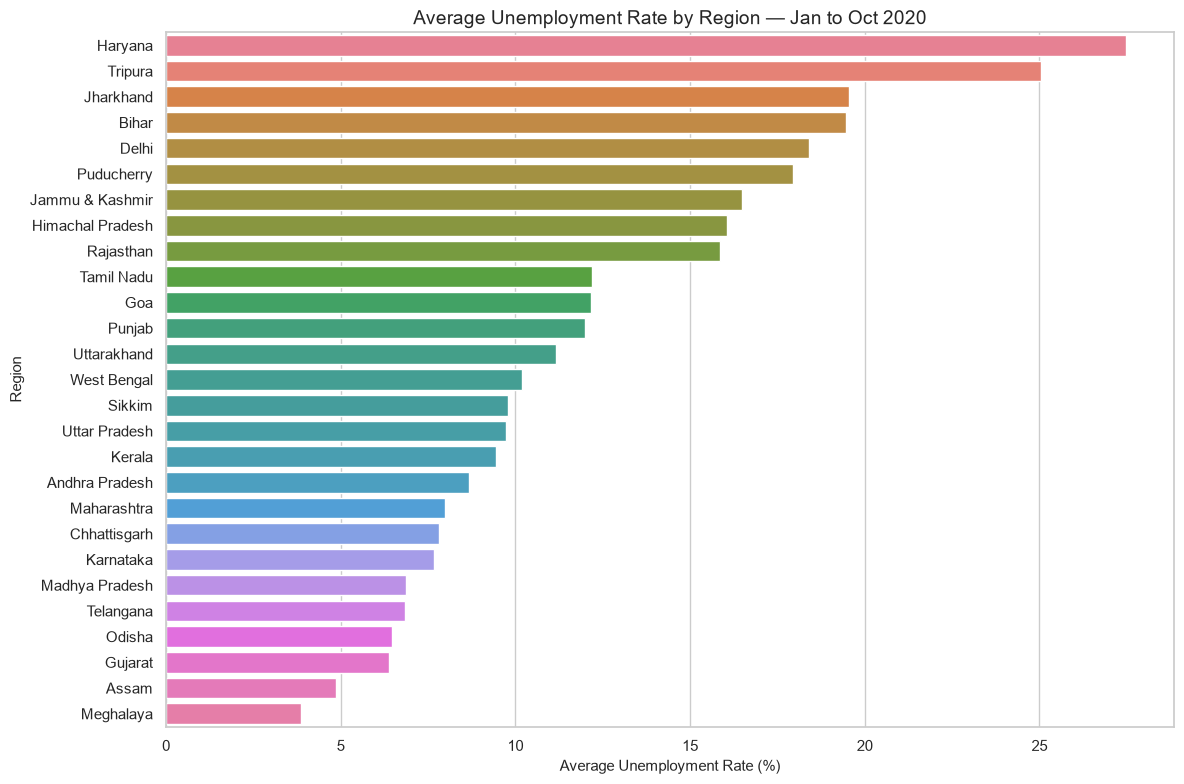

In [21]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=region_avg,
    x="Estimated Unemployment Rate (%)",
    y="Region",
    hue="Region",
    legend=False
)
plt.title("Average Unemployment Rate by Region — Jan to Oct 2020")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


### Observation

This ranking shows that unemployment was not uniform across Indian regions during the observed period. The highest- and lowest-average regions are calculated directly from the dataset, so the ordering will remain reproducible if the file is rerun.


## B. Month-wise Unemployment Trend

Monthly aggregation is used to examine the overall temporal movement in unemployment. Each month is averaged across the regions available for that month.


In [22]:
monthly_unemployment = (
    data.groupby("Date", as_index=False)["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values("Date")
)

display(monthly_unemployment)


,Date,Estimated Unemployment Rate (%)
0,2020-01-31,9.196538
1,2020-02-29,9.266154
2,2020-03-31,10.782593
3,2020-04-30,22.236154
4,2020-05-31,23.244444
5,2020-06-30,10.911111
6,2020-07-31,9.834444
7,2020-08-31,10.313333
8,2020-09-30,8.705926
9,2020-10-31,8.026296


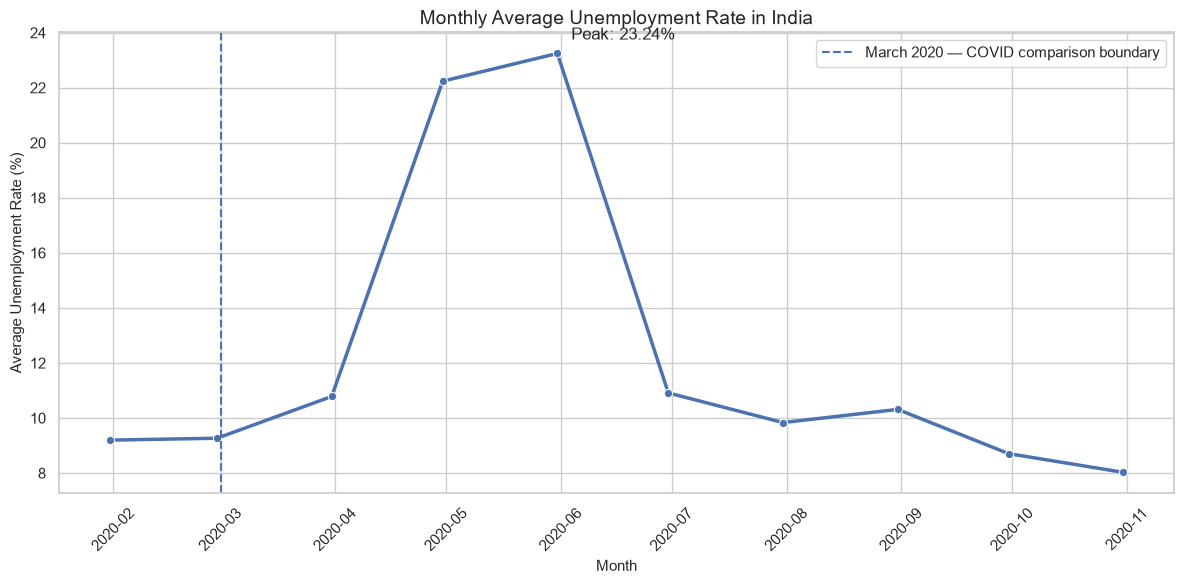

In [23]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o",
    linewidth=2.5
)

plt.axvline(
    COVID_DATE,
    linestyle="--",
    linewidth=1.5,
    label="March 2020 — COVID comparison boundary"
)

peak_row = monthly_unemployment.loc[
    monthly_unemployment["Estimated Unemployment Rate (%)"].idxmax()
]

plt.annotate(
    f"Peak: {peak_row['Estimated Unemployment Rate (%)']:.2f}%",
    xy=(peak_row["Date"], peak_row["Estimated Unemployment Rate (%)"]),
    xytext=(10, 10),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Observation

The monthly series makes the COVID-period disruption visible as a change in the unemployment trajectory. The peak month is identified dynamically from the data; the vertical marker separates observations before March 2020 from observations from March 2020 onward.


# 8. Time-Series Analysis by Major States/Regions

To avoid choosing states arbitrarily, the three regions with the greatest number of observations are selected. This gives the comparison the strongest available time coverage in the supplied file.


In [24]:
region_counts = data.groupby("Region").size().sort_values(ascending=False)
major_regions = region_counts.head(3).index.tolist()

print("Selected regions:", major_regions)
print("\nObservation counts:")
display(region_counts.head(10).to_frame("Observations"))


Selected regions: ['Andhra Pradesh', 'Assam', 'Bihar']

Observation counts:


,Observations
Region,
Andhra Pradesh,10
Assam,10
Bihar,10
Chhattisgarh,10
Delhi,10
Goa,10
Gujarat,10
Haryana,10
Himachal Pradesh,10


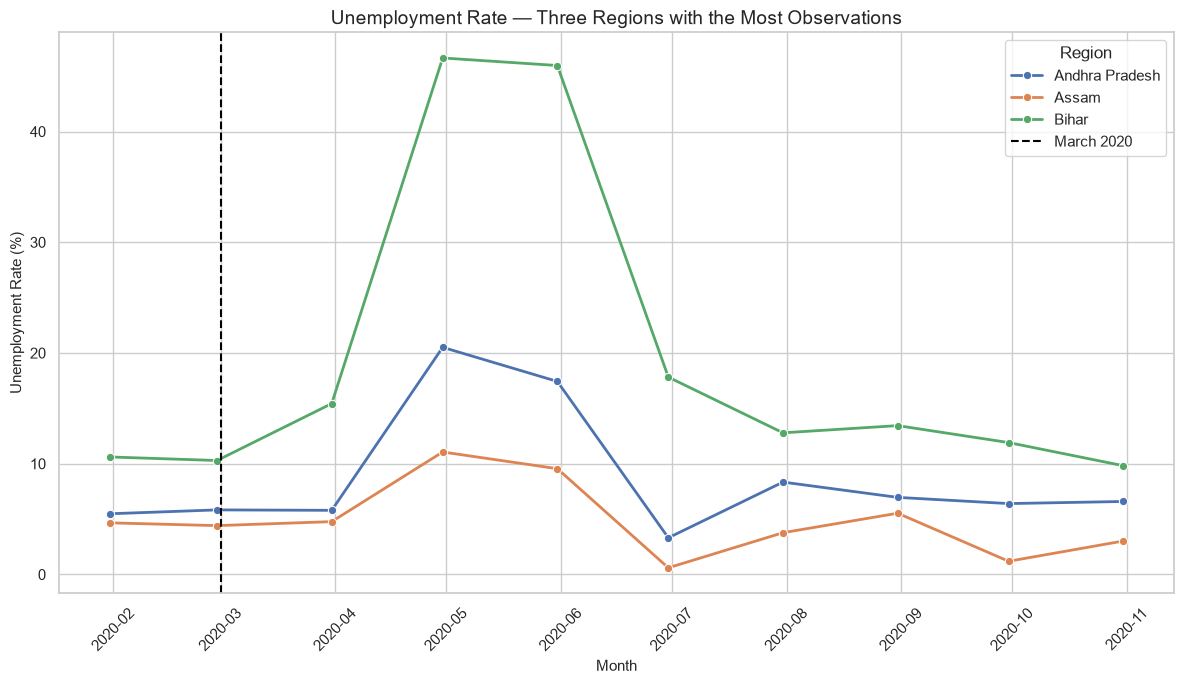

In [25]:
major_ts = data[data["Region"].isin(major_regions)].copy()

plt.figure(figsize=(12, 7))
sns.lineplot(
    data=major_ts,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o",
    linewidth=2
)

plt.axvline(
    COVID_DATE,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="March 2020"
)

plt.title("Unemployment Rate — Three Regions with the Most Observations")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()


In [26]:
major_summary = (
    major_ts.groupby("Region")["Estimated Unemployment Rate (%)"]
    .agg(["mean", "std", "max", "min"])
    .sort_values("mean", ascending=False)
)

display(major_summary)

highest_mean_major = major_summary["mean"].idxmax()
highest_volatility_major = major_summary["std"].idxmax()

print("Highest average unemployment among selected regions:", highest_mean_major)
print("Highest volatility (standard deviation):", highest_volatility_major)


,mean,std,max,min
Region,,,,
Bihar,19.471,14.348846,46.64,9.82
Andhra Pradesh,8.664,5.624360,20.51,3.31
Assam,4.856,3.288459,11.06,0.60


Highest average unemployment among selected regions: Bihar
Highest volatility (standard deviation): Bihar


### Observation

The three selected regions can be compared on both level and volatility. The standard deviation is used as a simple volatility measure; it describes variation in the observed unemployment rate but does not by itself identify the cause of that variation.


# 9. Top 10 States/Regions with Highest Average Unemployment

The top ten regions are displayed separately for an easy portfolio-style summary.


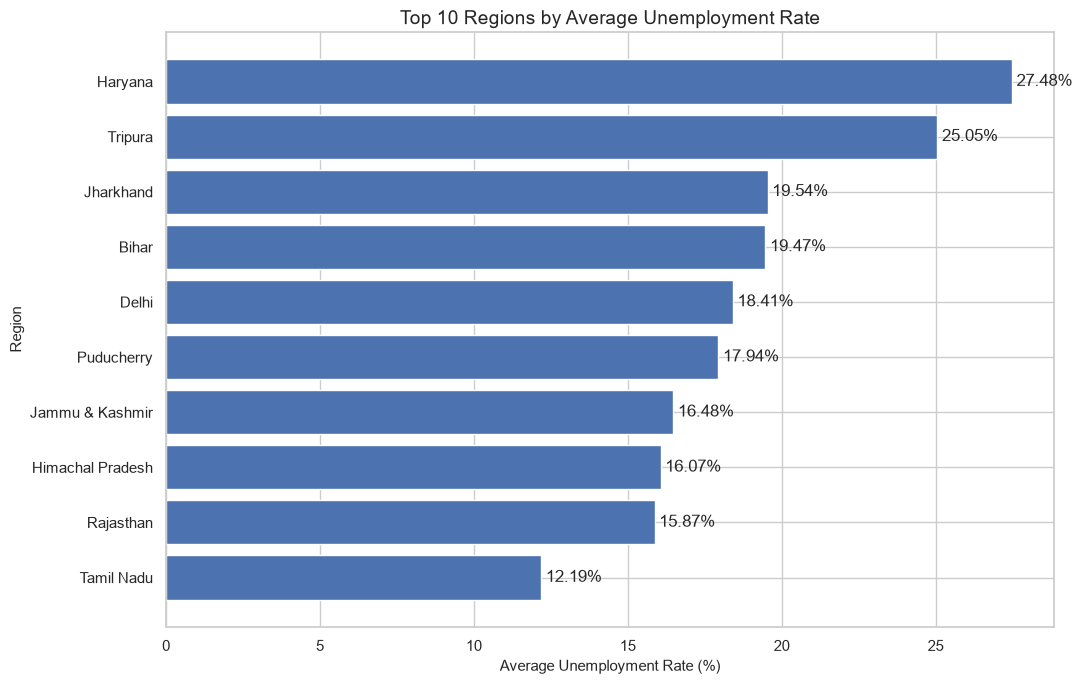

In [27]:
top10 = region_avg.head(10).sort_values("Estimated Unemployment Rate (%)")

plt.figure(figsize=(11, 7))
bars = plt.barh(
    top10["Region"],
    top10["Estimated Unemployment Rate (%)"]
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


### Observation

The top-ten chart highlights the regions whose average unemployment rate was highest during the dataset's January–October 2020 window. Because the ranking is based on averages, it should not be interpreted as a ranking of the single worst monthly unemployment event.


# 10. Correlation Analysis

The requested variables are:

- Unemployment Rate
- Employment Rate
- Labour Participation Rate

However, the selected dataset does **not** contain an employment-rate percentage. It contains `Estimated Employed`, an absolute employment count. Therefore, this section calculates the correlation among:

1. Estimated Unemployment Rate (%)
2. Estimated Employed (count)
3. Estimated Labour Participation Rate (%)

This is the closest valid analysis supported by the supplied data and avoids fabricating an employment-rate variable.


In [28]:
corr_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_matrix = data[corr_cols].corr()

display(correlation_matrix)


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.245176,-0.073540
Estimated Employed,-0.245176,1.000000,-0.047948
Estimated Labour Participation Rate (%),-0.073540,-0.047948,1.000000


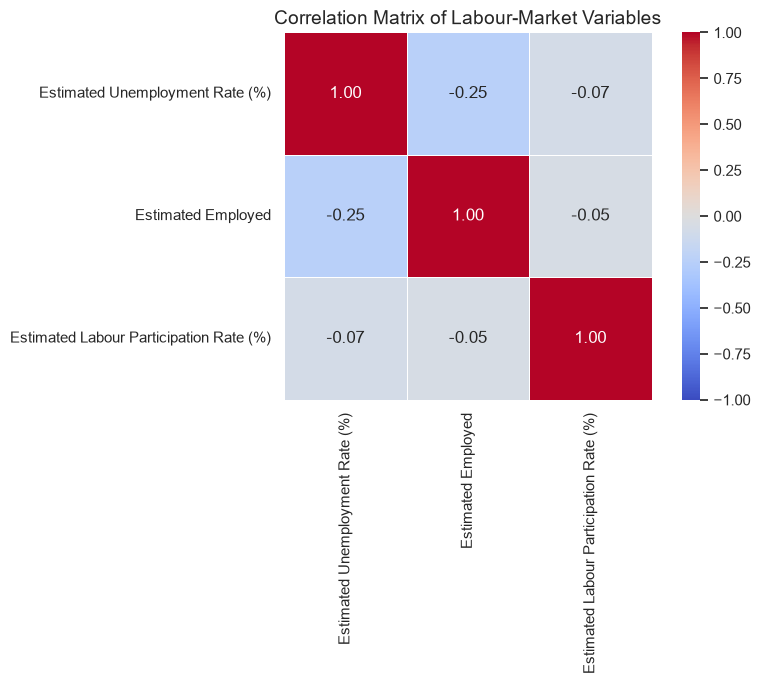

In [29]:
plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of Labour-Market Variables")
plt.tight_layout()
plt.show()


In [30]:
# Identify the strongest off-diagonal correlation.
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

strongest_pair = corr_pairs.abs().idxmax()
strongest_value = corr_pairs.loc[strongest_pair]

print("Strongest absolute correlation:")
print(f"{strongest_pair[0]} ↔ {strongest_pair[1]} = {strongest_value:.3f}")


Strongest absolute correlation:
Estimated Unemployment Rate (%) ↔ Estimated Employed = -0.245


### Observation

The heatmap shows the direction and strength of linear association among the three available measures. A positive or negative correlation indicates statistical association in this dataset; **correlation does not prove causation**, and the employment-count variable should not be interpreted as an employment rate.


# 11. COVID-19 Impact Analysis

## Pre-COVID vs Post-COVID

For consistency with the project specification, the boundary is:

- **Pre-COVID:** dates before 1 March 2020
- **Post-COVID:** 1 March 2020 onward

The comparison is observational. It can show differences between the two periods but cannot, by itself, prove that COVID-19 caused every observed change.


In [31]:
data["COVID_Period"] = np.where(
    data["Date"] < COVID_DATE,
    "Pre-COVID",
    "Post-COVID"
)

covid_metrics = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

period_means = (
    data.groupby("COVID_Period")[covid_metrics]
    .mean()
    .reindex(["Pre-COVID", "Post-COVID"])
)

display(period_means)


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
COVID_Period,,,
Pre-COVID,9.231346,1.556273e+07,44.403654
Post-COVID,12.963860,1.357498e+07,41.023209


In [32]:
pre = period_means.loc["Pre-COVID"]
post = period_means.loc["Post-COVID"]

absolute_change = post - pre
percentage_change = (absolute_change / pre) * 100

covid_comparison = pd.DataFrame({
    "Pre-COVID Mean": pre,
    "Post-COVID Mean": post,
    "Absolute Change": absolute_change,
    "Percentage Change (%)": percentage_change
})

display(covid_comparison)


,Pre-COVID Mean,Post-COVID Mean,Absolute Change,Percentage Change (%)
Estimated Unemployment Rate (%),9.231346e+00,1.296386e+01,3.732514e+00,40.433045
Estimated Employed,1.556273e+07,1.357498e+07,-1.987756e+06,-12.772536
Estimated Labour Participation Rate (%),4.440365e+01,4.102321e+01,-3.380445e+00,-7.612987


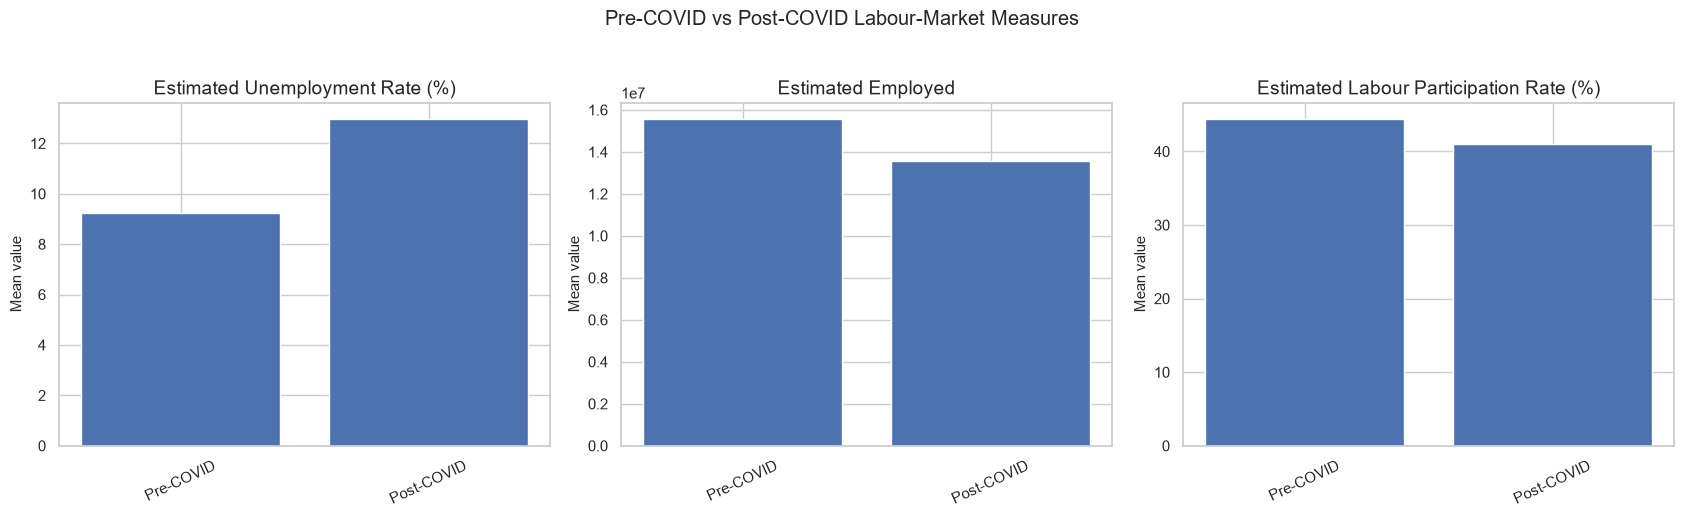

In [33]:
plot_metrics = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, plot_metrics):
    values = period_means[metric]
    ax.bar(values.index, values.values)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("Mean value")

plt.suptitle("Pre-COVID vs Post-COVID Labour-Market Measures", y=1.03)
plt.tight_layout()
plt.show()


### Observation

The comparison table quantifies how the three available labour-market measures changed between the two periods. In particular, the unemployment-rate change is directly interpretable as a percentage-point difference, while the employment measure is a change in estimated employed-person count. These are period differences, not causal estimates of the pandemic's effect.


# 12. Additional COVID-19 Analysis

## A. Month with the Highest Average Unemployment

This identifies the month with the highest cross-region average unemployment rate.


In [34]:
peak_month = monthly_unemployment.loc[
    monthly_unemployment["Estimated Unemployment Rate (%)"].idxmax()
]

print(
    f"Highest average unemployment month: "
    f"{peak_month['Date'].strftime('%B %Y')} "
    f"({peak_month['Estimated Unemployment Rate (%)']:.2f}%)"
)


Highest average unemployment month: May 2020 (23.24%)


### Observation

The peak month is determined from the monthly regional average. This is a dataset-level indicator and does not imply that every state experienced its individual peak in the same month.


## B. State/Region with the Largest Increase Around the COVID Boundary

For each region, compare its average unemployment rate before March 2020 with its average from March 2020 onward.


In [35]:
period_region = (
    data.groupby(["Region", "COVID_Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
)

period_region["Absolute Change"] = (
    period_region.get("Post-COVID") - period_region.get("Pre-COVID")
)

period_region = period_region.dropna(subset=["Pre-COVID", "Post-COVID"])
period_region = period_region.sort_values("Absolute Change", ascending=False)

display(period_region)

largest_increase_region = period_region["Absolute Change"].idxmax()
largest_increase_value = period_region["Absolute Change"].max()

print(
    f"Largest regional increase: {largest_increase_region} "
    f"({largest_increase_value:.2f} percentage points)"
)


COVID_Period,Post-COVID,Pre-COVID,Absolute Change
Region,,,
Puducherry,22.135000,1.170,20.965000
Tamil Nadu,14.776250,1.830,12.946250
Bihar,21.726250,10.450,11.276250
Jharkhand,21.616250,11.230,10.386250
Goa,13.746250,5.850,7.896250
Uttarakhand,12.635000,5.240,7.395000
Karnataka,8.776250,3.235,5.541250
Haryana,28.582500,23.055,5.527500
West Bengal,11.257500,5.930,5.327500


Largest regional increase: Puducherry (20.96 percentage points)


### Observation

The regional comparison shows that the COVID-period change was not necessarily uniform across India. Regions are ranked by the difference between their own pre- and post-period averages, which is more informative than comparing only their absolute unemployment levels.


## C. Recovery from the Peak

A simple recovery indicator compares the post-peak unemployment rate with the last observed month. This should be interpreted as movement within the available January–October 2020 window rather than a complete long-term recovery measure.


In [36]:
peak_date = monthly_unemployment.loc[
    monthly_unemployment["Estimated Unemployment Rate (%)"].idxmax(),
    "Date"
]

peak_value = monthly_unemployment.loc[
    monthly_unemployment["Date"].eq(peak_date),
    "Estimated Unemployment Rate (%)"
].iloc[0]

last_date = monthly_unemployment["Date"].max()
last_value = monthly_unemployment.loc[
    monthly_unemployment["Date"].eq(last_date),
    "Estimated Unemployment Rate (%)"
].iloc[0]

print(f"Peak monthly average: {peak_value:.2f}% in {peak_date.strftime('%B %Y')}")
print(f"Last observed monthly average: {last_value:.2f}% in {last_date.strftime('%B %Y')}")
print(f"Change from peak to last observation: {last_value - peak_value:.2f} percentage points")


Peak monthly average: 23.24% in May 2020
Last observed monthly average: 8.03% in October 2020
Change from peak to last observation: -15.22 percentage points


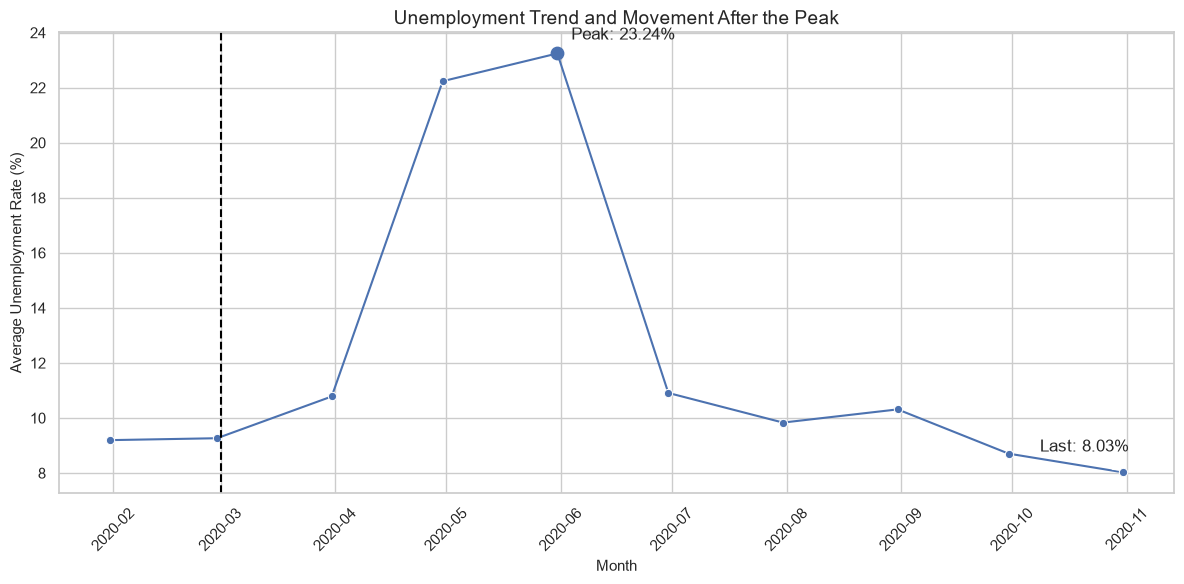

In [37]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.axvline(COVID_DATE, linestyle="--", linewidth=1.5, color="black")
plt.scatter([peak_date], [peak_value], s=80, zorder=5)

plt.annotate(
    f"Peak: {peak_value:.2f}%",
    xy=(peak_date, peak_value),
    xytext=(10, 10),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    f"Last: {last_value:.2f}%",
    xy=(last_date, last_value),
    xytext=(-60, 15),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.title("Unemployment Trend and Movement After the Peak")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Observation

A decline from the peak toward the end of the observed window would indicate partial recovery within the dataset. It should not be described as a full recovery because the file ends in October 2020 and does not cover the subsequent labour-market period.


# 13. Regional Differences and Geographic Context

The selected file contains a broad zone field (`Region.1`). This section summarizes average unemployment by zone when that field is available.


In [38]:
zone_avg = (
    data.groupby("Region.1", as_index=False)["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values("Estimated Unemployment Rate (%)", ascending=False)
)

display(zone_avg)


,Region.1,Estimated Unemployment Rate (%)
1,North,15.889620
0,East,13.916000
2,Northeast,10.950263
3,South,10.454667
4,West,8.239000


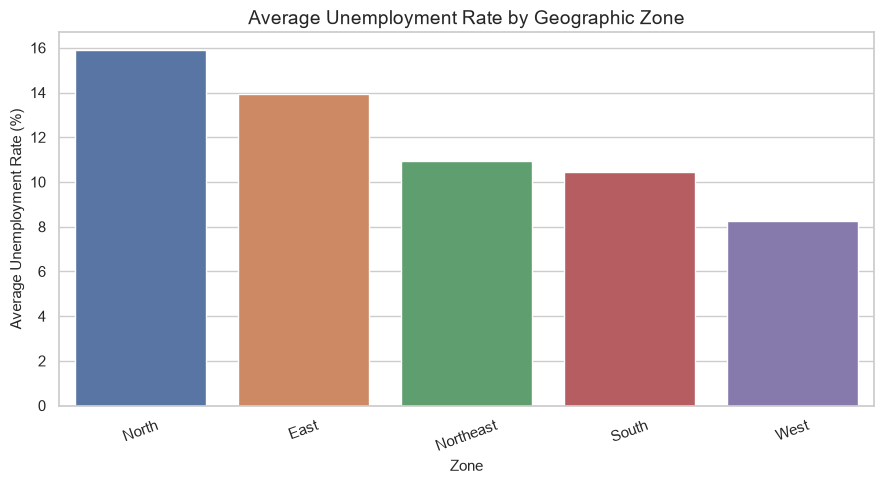

In [39]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=zone_avg,
    x="Region.1",
    y="Estimated Unemployment Rate (%)",
    hue="Region.1",
    legend=False
)

plt.title("Average Unemployment Rate by Geographic Zone")
plt.xlabel("Zone")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Observation

Zone-level aggregation provides a broader geographic view of the regional differences already observed at state level. Zone averages should be treated as summaries of the states represented in this particular dataset rather than as official regional estimates for the whole Indian labour market.


# 14. Key Findings

The following bullets are generated from the calculated results so that the notebook remains reproducible.


In [40]:
# Dynamic summary values for the final findings.
overall_mean = data["Estimated Unemployment Rate (%)"].mean()
highest_avg_region = region_avg.iloc[0]["Region"]
highest_avg_value = region_avg.iloc[0]["Estimated Unemployment Rate (%)"]
lowest_avg_region = region_avg.iloc[-1]["Region"]
lowest_avg_value = region_avg.iloc[-1]["Estimated Unemployment Rate (%)"]

unemp_abs_change = covid_comparison.loc[
    "Estimated Unemployment Rate (%)", "Absolute Change"
]
unemp_pct_change = covid_comparison.loc[
    "Estimated Unemployment Rate (%)", "Percentage Change (%)"
]

print(f"1. Overall mean unemployment rate: {overall_mean:.2f}%.")
print(
    f"2. Highest regional average: {highest_avg_region} "
    f"({highest_avg_value:.2f}%)."
)
print(
    f"3. Lowest regional average: {lowest_avg_region} "
    f"({lowest_avg_value:.2f}%)."
)
print(
    f"4. Peak monthly average: {peak_month['Estimated Unemployment Rate (%)']:.2f}% "
    f"in {peak_month['Date'].strftime('%B %Y')}."
)
print(
    f"5. Pre-COVID to post-COVID unemployment change: "
    f"{unemp_abs_change:.2f} percentage points "
    f"({unemp_pct_change:.2f}% relative change)."
)
print(
    f"6. Largest regional pre/post increase: {largest_increase_region} "
    f"({largest_increase_value:.2f} percentage points)."
)
print(
    "7. The correlation analysis uses Estimated Employed (count), "
    "because an employment-rate percentage is not supplied."
)
print(
    "8. These findings are observational and do not establish COVID-19 causality."
)


1. Overall mean unemployment rate: 12.24%.
2. Highest regional average: Haryana (27.48%).
3. Lowest regional average: Meghalaya (3.87%).
4. Peak monthly average: 23.24% in May 2020.
5. Pre-COVID to post-COVID unemployment change: 3.73 percentage points (40.43% relative change).
6. Largest regional pre/post increase: Puducherry (20.96 percentage points).
7. The correlation analysis uses Estimated Employed (count), because an employment-rate percentage is not supplied.
8. These findings are observational and do not establish COVID-19 causality.


### Interpretation

- Regional unemployment varies substantially across the states represented in the dataset.
- The monthly series captures a pronounced change during the early COVID-19 period and subsequent movement toward lower unemployment later in the observed window.
- The three-region comparison demonstrates that both unemployment levels and volatility can differ across states.
- The top-ten ranking identifies the regions with the highest **average** unemployment, not necessarily the highest single-month peak.
- Correlations describe statistical relationships among the available variables; they do not establish causation.
- The pre-/post-COVID comparison provides evidence of a change in labour-market conditions around March 2020, but the dataset alone cannot prove that COVID-19 was the sole cause.


# 15. Conclusion

The selected India unemployment dataset provides a useful state-level and monthly view of unemployment during 2020, including the critical months surrounding the COVID-19 disruption. The analysis shows meaningful regional differences and a strong temporal shift around the March–May 2020 period, followed by lower unemployment levels later in the available window.

The dataset supports a clear observational comparison between pre-COVID and post-COVID periods. However, the analysis should not be interpreted as causal evidence because it does not control for other economic, seasonal, regional, or measurement factors. In addition, the selected dataset does not provide an employment-rate percentage; it provides an estimated employment count. That distinction is preserved throughout the notebook to avoid overstating what the data can support.

The results therefore answer the central project question at the EDA level: unemployment varied substantially across Indian regions and over time, and the dataset shows a marked change in unemployment and related labour-market measures during the COVID-19 period. The evidence is descriptive rather than causal.


# 16. Dataset Source

- **Dataset:** Unemployment in India / `Unemployment_Rate_upto_11_2020.csv`
- **Platform:** Kaggle
- **Dataset URL:** https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india
- **Underlying source identified in the Kaggle description:** Centre for Monitoring Indian Economy (CMIE)

## Libraries Used

- Python
- pandas
- NumPy
- matplotlib
- seaborn
- Jupyter Notebook


# 17. Final Checklist

- [x] Dataset sourced and documented
- [x] Original/public source URL provided
- [x] Data loading
- [x] Shape inspection
- [x] Null-value analysis
- [x] Data-type conversion
- [x] Data cleaning and validation
- [x] Region-wise average unemployment
- [x] Month-wise unemployment trends
- [x] Time-series chart for at least 3 regions
- [x] Top 10 regions by average unemployment
- [x] Correlation heatmap
- [x] Pre-COVID vs post-COVID comparison
- [x] Absolute and percentage changes
- [x] Additional COVID-period analysis
- [x] Written observations after major analyses
- [x] Reproducible, commented Python code
- [x] Key findings
- [x] Conclusion
- [x] Dataset limitations explicitly documented
- [x] No fabricated employment-rate variable or hard-coded analytical results
